# Milestone 8 — Model Testing and Performance Evaluation
**Study:** Obfuscation-Aware Feature Engineering for Evasion-Heavy Phishing URL Detection

This notebook independently reloads all **15 saved Module 7 models** and the separate Module 6 baseline, verifies their integrity, and evaluates the **same saved 2,000-row test partition**. No fitting, grid search, or threshold selection occurs here. The primary decision rule is **P(phishing) ≥ 0.5**, as stated in the proposal. The tuned thresholds are a separately labelled sensitivity analysis.

**Read before drawing conclusions:** Module 5 fitted its scalers on all 10,000 rows, including validation and test rows. Modules 6 and 7 already displayed test scores. These are therefore **provisional results from the existing experiment**, not a newly untouched test. Reproducing a score establishes that the saved training output works; it does not establish leakage-free generalization, zero-day detection, or causal effects of obfuscation. Correct training must fit scaling inside each CV pipeline on raw features. A future independent, domain-disjoint/temporal dataset is needed for stronger confirmation.

The proposal Table 4.1 and current repository define **3 Level 1 + 10 Level 2 = 13** features. The milestone form's six/seven wording conflicts with that definition; this notebook follows the final proposal's explicit feature allocation and Modules 3–7.

**Run:** extract the supplied bundle into the repository root and run this notebook from `Modules/` or the root, then run Module 9. Inputs must remain together under `Dataset/`, `Models/`, `Metrics/`, and `Modules/`. Only load trusted joblib files; the supplied model manifest is verified before deserialization. The original snapshot reviewed was commit `1178f6aa41318b34f7b7c8522cf1f867cb74f06b`.

Dependencies (install in your notebook kernel if needed): `pandas numpy matplotlib scipy psutil joblib nbformat scikit-learn==1.7.1 xgboost==3.4.1 tldextract threadpoolctl`. Matching training library versions is recommended for persisted models. This notebook records actual runtime versions.

In [1]:
from pathlib import Path
import io, os, sys, json, hashlib, time, platform, warnings, threading, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, xgboost, psutil, scipy, tldextract
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import (confusion_matrix, f1_score, accuracy_score, precision_score,
    recall_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    brier_score_loss)
from sklearn.calibration import calibration_curve
from scipy.stats import binomtest
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'Dataset/Final_Dataset.csv').is_file() and (p/'Metrics/models_manifest.csv').is_file()), None)
assert ROOT is not None, 'Run inside the PhishEvade repository (root or Modules).'
OUT = ROOT/'Results/milestone8'; OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT/'figures'; FIG.mkdir(exist_ok=True)
SEED=42; THRESHOLD=0.5; N_BOOT=2000; LATENCY_REPEATS=1
L1=['url_length','domain_length','path_length']
L2=['subdomain_count','path_depth','query_params_count','digit_ratio','special_char_ratio',
    'token_variance','domain_entropy','redirect_key_flag','nested_url_flag','query_encoding_ratio']
FS={'Level 1':L1,'Level 2':L2,'Combined':L1+L2}
CLASSIFIERS=['Logistic Regression','Random Forest','XGBoost','Naive Bayes','AdaBoost']
MM=['url_length','domain_length','path_length','digit_ratio','special_char_ratio','query_encoding_ratio']
ZS=['subdomain_count','path_depth','query_params_count','token_variance','domain_entropy']
thread_limits = threadpool_limits(limits=1)  # keep native thread counts comparable
pd.set_option('display.max_columns',40)
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_table(frame,name):
    frame.to_csv(OUT/(name+'.csv'),index=False)
    return frame

def figure(name):
    plt.tight_layout()
    buf=io.BytesIO()
    plt.savefig(buf,format='png',dpi=150,bbox_inches='tight')
    (FIG/(name+'.png')).write_bytes(buf.getvalue())
    plt.show(); plt.close()
def slug(s):return s.lower().replace(' ','_').replace('+','plus')
def key(c,f):return slug(c)+'__'+slug(f)
print('Repository:',ROOT)
print('Primary threshold:',THRESHOLD,'| bootstrap repetitions:',N_BOOT)

Repository: /workspace/scratch/e3e5f7f7f0e0/full_repo
Primary threshold: 0.5 | bootstrap repetitions: 2000


## 1. Input, partition, scaling, and artifact audit
Checks fail immediately for missing/mismatched models, rows, labels, features, checksums, or baseline results. CSV row positions remain the sample identifiers; URLs are read only as strings and are never visited. The exact data hashes are saved for future reproducibility.

In [2]:
data=pd.read_csv(ROOT/'Dataset/Final_Dataset.csv')
raw=pd.read_csv(ROOT/'Dataset/Extracted_Features.csv')
pre=pd.read_csv(ROOT/'Dataset/Preprocessed_Dataset.csv',keep_default_na=False)
record=json.loads((ROOT/'Metrics/all_models_metrics.json').read_text())
manifest=pd.read_csv(ROOT/'Metrics/models_manifest.csv')
split=pd.read_csv(ROOT/'Models/train_test_split_indices.csv')
assert list(data.columns)==L1+L2+['label']
assert len(data)==len(raw)==len(pre)==10000
assert data.label.value_counts().to_dict()=={0:5000,1:5000}
assert raw.label.equals(data.label) and np.array_equal(pre.label,data.label)
assert raw.url.equals(pre.url), 'URL order differs between raw-feature and preprocessing files.'
assert np.isfinite(data.to_numpy(float)).all() and np.isfinite(raw[L1+L2].to_numpy(float)).all()
assert raw.url.notna().all() and raw.url.str.len().gt(0).all()
assert len(split)==len(data) and split.row_index.is_unique
assert set(split.row_index)==set(range(len(data))) and set(split['split'])=={'train','test'}
y=data.label.to_numpy(int)
train_idx,test_idx=train_test_split(np.arange(len(data)),test_size=.2,stratify=y,random_state=SEED)
saved_test=split.loc[split['split']=='test','row_index'].to_numpy(int)
assert np.array_equal(np.sort(test_idx),np.sort(saved_test))
assert len(train_idx)==8000 and len(test_idx)==2000 and not np.intersect1d(train_idx,test_idx).size
yt=y[test_idx]; yr=y[train_idx]
assert np.bincount(yt).tolist()==[1000,1000]

# Reconstruct Module 5's full-corpus scaling to validate file lineage AND document leakage.
reconstructed=raw[L1+L2].astype(float).copy()
reconstructed[MM]=MinMaxScaler().fit_transform(raw[MM])
reconstructed[ZS]=StandardScaler().fit_transform(raw[ZS])
assert np.allclose(reconstructed,data[L1+L2],rtol=1e-7,atol=1e-10)
train_scaled=raw[L1+L2].astype(float).copy()
for cols,scaler in [(MM,MinMaxScaler()),(ZS,StandardScaler())]:
    scaler.fit(raw.iloc[train_idx][cols]); train_scaled[cols]=scaler.transform(raw[cols])
scaling_diff=(train_scaled.iloc[test_idx]-data.iloc[test_idx][L1+L2]).abs()
save_table(pd.DataFrame({'feature':L1+L2,'mean_absolute_test_scaling_difference':scaling_diff.mean().values,
                        'max_absolute_test_scaling_difference':scaling_diff.max().values}), 'scaling_leakage_diagnostic')
expected={(c,f) for c in CLASSIFIERS for f in FS}
assert set(zip(manifest.classifier,manifest.feature_set))==expected and len(manifest)==15
assert {(m['classifier'],m['feature_set']) for m in record['models']}==expected and len(record['models'])==15
bundles={}; model_audit=[]
for row in manifest.itertuples():
    # Resolve by declared classifier/configuration, ignoring original machine's Windows paths.
    k=key(row.classifier,row.feature_set); p=ROOT/'Models'/f'{k}.joblib'
    assert p.is_file() and sha(p)==row.sha256, f'Checksum failed: {p.name}'
    b=joblib.load(p)
    assert b['features']==FS[row.feature_set] and b['classifier']==row.classifier and b['feature_set']==row.feature_set
    assert list(b['model'].classes_)==[0,1] and b['model'].n_features_in_==len(b['features'])
    assert b['threshold_default']==.5
    bundles[k]=b
    model_audit.append({'combination':k,'file':p.name,'sha256':sha(p),'n_features':len(b['features']),
                        'model_size_mb':p.stat().st_size/2**20,'manifest_verified':True})
save_table(pd.DataFrame(model_audit),'artifact_verification')
base_bundle=joblib.load(ROOT/'Models/baseline_logistic_regression.joblib')
assert base_bundle['features']==L1
base_proba=base_bundle['model'].predict_proba(data.iloc[test_idx][L1].to_numpy(float))[:,1]
BASE=key('Logistic Regression','Level 1')
np.testing.assert_allclose(base_proba,bundles[BASE]['model'].predict_proba(data.iloc[test_idx][L1].to_numpy(float))[:,1],atol=1e-9,rtol=1e-7)

# Registered domains use the offline Public Suffix List snapshot, not a last-two-label shortcut.
extract=tldextract.TLDExtract(suffix_list_urls=(),cache_dir=None)
def domain(u):
    e=extract(str(u)); return e.top_domain_under_public_suffix or e.fqdn or str(u).split('/')[0]
domains=raw.url.map(domain)
seen=domains.iloc[test_idx].isin(set(domains.iloc[train_idx])).to_numpy()
exact_url_seen=raw.url.iloc[test_idx].isin(set(raw.url.iloc[train_idx])).to_numpy()
feature_overlap=pd.MultiIndex.from_frame(raw.iloc[test_idx][L1+L2]).isin(pd.MultiIndex.from_frame(raw.iloc[train_idx][L1+L2]))
quality=pd.DataFrame([
 {'check':'rows','value':len(data)}, {'check':'train rows','value':len(train_idx)},
 {'check':'test rows','value':len(test_idx)}, {'check':'test benign','value':int((yt==0).sum())},
 {'check':'test phishing','value':int((yt==1).sum())},
 {'check':'test URLs whose registered domain occurs in training','value':int(seen.sum())},
 {'check':'test rows with exact 13-feature vector in training','value':int(feature_overlap.sum())},
 {'check':'test URLs repeated verbatim in training','value':int(exact_url_seen.sum())},
 {'check':'normalized URLs with conflicting labels','value':int(raw.groupby('url').label.nunique().gt(1).sum())},
 {'check':'duplicate normalized URLs','value':int(raw.url.duplicated().sum())},
 {'check':'raw duplicate feature vectors (may be different URLs)','value':int(raw[L1+L2].duplicated().sum())}])
save_table(quality,'data_quality');display(quality)
print('PASS: 15 model checksums, fixed feature order, saved split, file alignment, and separate baseline verified.')
print('CONFIRMED LIMITATION: Final_Dataset.csv reproduces scaling fitted on all 10,000 rows.')

PASS: 15 model checksums, fixed feature order, saved split, file alignment, and separate baseline verified.
CONFIRMED LIMITATION: Final_Dataset.csv reproduces scaling fitted on all 10,000 rows.


,check,value
0,rows,10000
1,train rows,8000
2,test rows,2000
3,test benign,1000
4,test phishing,1000
5,test URLs whose registered domain occurs in tr...,1044
6,test rows with exact 13-feature vector in trai...,614
7,test URLs repeated verbatim in training,1
8,normalized URLs with conflicting labels,0
9,duplicate normalized URLs,7


## 2. Independent predictions and all 15 primary comparisons
Phishing is positive (`1`). FPR = FP/(FP+TN); FNR = FN/(TP+FN). A true zero denominator is reported as missing for rates that cannot be estimated. Precision/F1 use zero when no positive prediction exists. ROC-AUC and average precision are supplementary ranking metrics. The “obfuscation score” is the model's phishing probability estimate; labels do not establish it as a calibrated probability of evasion.

Training time and peak training RSS are historical measurements from Module 7 on its recorded machine. New inference measurements use this runtime and are labelled separately. They are model-only, single-URL `predict_proba` timings, excluding feature extraction and network time. Peak RSS includes the process and already retained models, so it is not isolated per-model memory consumption.

In [3]:
def metrics(y_true,p,threshold=.5):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    div=lambda a,b: float(a/b) if b else np.nan
    return dict(n=len(y_true),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
        accuracy=div(tp+tn,len(y_true)),precision=div(tp,tp+fp) if tp+fp else 0.,
        recall=div(tp,tp+fn),f1=div(2*tp,2*tp+fp+fn) if 2*tp+fp+fn else 0.,
        fpr=div(fp,fp+tn),fnr=div(fn,tp+fn),
        roc_auc=roc_auc_score(y_true,p) if len(np.unique(y_true))==2 else np.nan,
        average_precision=average_precision_score(y_true,p) if (y_true==1).any() else np.nan,
        brier=brier_score_loss(y_true,p) if len(y_true) else np.nan)
# Hand-computed unit check for the evaluator: TN=1, FP=1, FN=1, TP=1.
m=metrics(np.array([0,0,1,1]),np.array([.1,.8,.3,.9]))
assert [m[x] for x in ['tn','fp','fn','tp']]==[1,1,1,1]
assert all(m[x]==.5 for x in ['accuracy','precision','recall','f1','fpr','fnr'])
assert np.array_equal((np.array([.499,.5,.501])>=.5).astype(int),[0,1,1])

predictions={}; probabilities={}; rows=[]; sensitivity=[]; drift=[]; latency_rows=[]
for source in record['models']:
    c,f=source['classifier'],source['feature_set']; k=key(c,f); b=bundles[k]
    model=b['model']; X=data.iloc[test_idx][b['features']].to_numpy(float)
    if hasattr(model,'n_jobs'): model.set_params(n_jobs=1)
    p=model.predict_proba(X)[:,1]
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    np.testing.assert_allclose(model.predict_proba(X)[:,1],p,atol=1e-12)
    probabilities[k]=p;predictions[k]=(p>=THRESHOLD).astype(int)
    met=metrics(yt,p)
    previous=source['test_metrics']['default (0.5)']
    for field in ['accuracy','precision','recall','f1','fpr','tn','fp','fn','tp']:
        assert np.isclose(met[field],previous[field],atol=1e-9), f'Module 7 metric drift: {k}/{field}'
    ptrain=model.predict_proba(data.iloc[train_idx][b['features']].to_numpy(float))[:,1]
    r=source['resources']['training']
    row=dict(combination=k,classifier=c,feature_set=f,n_features=len(b['features']),threshold=.5,**met,
        cv_f1=source['cv_f1'],cv_f1_std=source['cv_f1_std'],
        resubstitution_train_f1=f1_score(yr,ptrain>=.5),
        training_time_s_historical=r['wall_time_s'],training_peak_rss_mb_historical=r['peak_memory_mb'],
        training_peak_rss_increase_mb_historical=r['peak_memory_increase_mb'],
        inference_ms_per_url_historical=source['resources']['inference_latency']['mean_ms'],
        best_params=json.dumps(source['best_params']))
    for i in range(min(20,len(X))): model.predict_proba(X[i:i+1])
    times=[]
    for rep in range(LATENCY_REPEATS):
        for i in np.random.default_rng(SEED+rep).permutation(len(X)):
            t=time.perf_counter_ns(); model.predict_proba(X[i:i+1]); times.append((time.perf_counter_ns()-t)/1e6)
    row.update(inference_mean_ms_current=float(np.mean(times)),inference_p50_ms_current=float(np.median(times)),
               inference_p95_ms_current=float(np.percentile(times,95)),timed_calls=len(times))
    rows.append(row)
    for t in [source['threshold']['tuned']]:
        sensitivity.append(dict(combination=k,threshold=t,rule='training-OOF Youden J; exploratory',**metrics(yt,p,t)))
    print(c,'/',f,': F1',round(met['f1'],4),'| historical metrics reproduced')
results=pd.DataFrame(rows)
base=results.set_index('combination').loc[BASE]
for metric in ['accuracy','precision','recall','f1','fpr','fnr']:
    results['delta_'+metric+'_vs_baseline_pp']=100*(results[metric]-base[metric])
results['train_minus_test_f1']=results.resubstitution_train_f1-results.f1
results['test_minus_cv_f1']=results.f1-results.cv_f1
save_table(pd.DataFrame(sensitivity),'tuned_threshold_sensitivity')
# Verify the independently loaded Module 6 baseline against both its metrics file and Module 7.
base_saved=pd.read_csv(ROOT/'Metrics/baseline_metrics.csv')
base_saved=base_saved.loc[base_saved.threshold_rule=='default (0.5)'].iloc[0]
for metric in ['accuracy','precision','recall','f1','fpr']:
    assert np.isclose(base[metric],base_saved[metric],atol=1e-9)
print('PASS: all 15 primary confusion matrices/metrics reproduce Module 7; Module 6 baseline agrees.')

Logistic Regression / Level 1 : F1 0.6283 | historical metrics reproduced
Logistic Regression / Level 2 : F1 0.6394 | historical metrics reproduced
Logistic Regression / Combined : F1 0.6649 | historical metrics reproduced
Random Forest / Level 1 : F1 0.8814 | historical metrics reproduced
Random Forest / Level 2 : F1 0.9158 | historical metrics reproduced
Random Forest / Combined : F1 0.9419 | historical metrics reproduced
XGBoost / Level 1 : F1 0.8783 | historical metrics reproduced
XGBoost / Level 2 : F1 0.9184 | historical metrics reproduced
XGBoost / Combined : F1 0.9463 | historical metrics reproduced
Naive Bayes / Level 1 : F1 0.7298 | historical metrics reproduced
Naive Bayes / Level 2 : F1 0.6981 | historical metrics reproduced
Naive Bayes / Combined : F1 0.6995 | historical metrics reproduced
AdaBoost / Level 1 : F1 0.8648 | historical metrics reproduced
AdaBoost / Level 2 : F1 0.8735 | historical metrics reproduced
AdaBoost / Combined : F1 0.9275 | historical metrics reprodu

## 3. Uncertainty and paired feature comparisons
A fixed seed generates 2,000 **class-stratified, paired bootstrap** resamples of the same test rows. The percentile intervals describe uncertainty conditional on these fitted models and this balanced sample. They exclude training/model-selection uncertainty, domain dependence, and preprocessing leakage. They must not be used to claim those issues are resolved.

Comparisons include all 14 non-baseline combinations versus the global LR baseline, and Level 2/Combined versus Level 1 **within each classifier** (24 contrasts). Within-classifier comparisons are the useful feature-ablation test; comparison only with LR also changes algorithm capacity. A paired randomization test assesses F1 differences by swapping model predictions within URLs (4,999 draws). Exact two-sided McNemar tests assess paired **overall errors**, not F1. One-sided paired tests restricted to benign rows assess reduced FPR. Holm adjustment covers all 24 contrasts separately for each of the three test families. F1-difference CIs are exploratory, unadjusted 95% intervals, not simultaneous significance claims. No model/threshold is chosen by these tests.

In [4]:
rng=np.random.default_rng(SEED)
neg=np.flatnonzero(yt==0); pos=np.flatnonzero(yt==1)
boot_idx=np.concatenate([rng.choice(neg,(N_BOOT,len(neg)),replace=True),
                         rng.choice(pos,(N_BOOT,len(pos)),replace=True)],axis=1)
boot={}
for k,pred in predictions.items():
    bp=pred[boot_idx];fp=bp[:,:len(neg)].sum(axis=1);tp=bp[:,len(neg):].sum(axis=1)
    fn=len(pos)-tp;tn=len(neg)-fp
    boot[k]={'f1':2*tp/(2*tp+fp+fn),'recall':tp/len(pos),'fpr':fp/len(neg),
             'accuracy':(tp+tn)/len(yt)}
for metric in ['f1','recall','fpr','accuracy']:
    results[metric+'_ci_low']=[np.quantile(boot[k][metric],.025) for k in results.combination]
    results[metric+'_ci_high']=[np.quantile(boot[k][metric],.975) for k in results.combination]

def holm(ps):
    ps=np.asarray(ps); order=np.argsort(ps); adjusted=np.empty(len(ps));last=0.
    for rank,i in enumerate(order):
        last=max(last,(len(ps)-rank)*ps[i]);adjusted[i]=min(1.,last)
    return adjusted
assert np.allclose(holm([.01,.04,.03]),[.03,.06,.06])
contrasts=[('vs global LR baseline',k,BASE) for k in predictions if k!=BASE]
contrasts += [('within-classifier feature ablation',key(c,f),key(c,'Level 1')) for c in CLASSIFIERS for f in ['Level 2','Combined']]
paired=[]
perm_test_rng=np.random.default_rng(SEED+1)
for family,k,ref in contrasts:
    correct=predictions[k]==yt; correct_ref=predictions[ref]==yt
    wins=int((correct & ~correct_ref).sum());losses=int((~correct & correct_ref).sum())
    fpr_wins=int(((predictions[k][neg]==0)&(predictions[ref][neg]==1)).sum())
    fpr_losses=int(((predictions[k][neg]==1)&(predictions[ref][neg]==0)).sum())
    d=boot[k]['f1']-boot[ref]['f1']; dfpr=boot[k]['fpr']-boot[ref]['fpr']
    a=results.set_index('combination').loc[k];b=results.set_index('combination').loc[ref]
    # Under the paired exchangeability null, each discordant prediction can swap.
    # Binomial draws count those swaps by true class without allocating a row matrix.
    pa,pb=predictions[k],predictions[ref]
    discord_pos=int((pa[pos]!=pb[pos]).sum()); discord_neg=int((pa[neg]!=pb[neg]).sum())
    shared_tp=int(((pa[pos]==1)&(pb[pos]==1)).sum()); shared_fp=int(((pa[neg]==1)&(pb[neg]==1)).sum())
    tp_a=shared_tp+perm_test_rng.binomial(discord_pos,.5,4999)
    fp_a=shared_fp+perm_test_rng.binomial(discord_neg,.5,4999)
    tp_b=2*shared_tp+discord_pos-tp_a; fp_b=2*shared_fp+discord_neg-fp_a
    perm_d=2*tp_a/(len(pos)+tp_a+fp_a)-2*tp_b/(len(pos)+tp_b+fp_b)
    p_f1=(1+int((np.abs(perm_d)>=abs(a.f1-b.f1)-1e-12).sum()))/5000
    paired.append(dict(family=family,combination=k,reference=ref,f1_permutation_p=p_f1,
        delta_f1_pp=100*(a.f1-b.f1),delta_f1_ci_low_pp=100*np.quantile(d,.025),delta_f1_ci_high_pp=100*np.quantile(d,.975),
        delta_fpr_pp=100*(a.fpr-b.fpr),delta_fpr_ci_low_pp=100*np.quantile(dfpr,.025),delta_fpr_ci_high_pp=100*np.quantile(dfpr,.975),
        corrected_errors=wins,introduced_errors=losses,
        mcnemar_p=binomtest(wins,wins+losses,.5).pvalue if wins+losses else 1.,
        reduced_fp=fpr_wins,introduced_fp=fpr_losses,
        fpr_reduction_p=binomtest(fpr_wins,fpr_wins+fpr_losses,.5,alternative='greater').pvalue if fpr_wins+fpr_losses else 1.))
paired=pd.DataFrame(paired)
paired['f1_permutation_p_holm']=holm(paired.f1_permutation_p)
paired['mcnemar_p_holm']=holm(paired.mcnemar_p)
paired['fpr_reduction_p_holm']=holm(paired.fpr_reduction_p)
save_table(paired,'paired_comparisons');save_table(results,'performance_comparison_15')
display(results[['classifier','feature_set','accuracy','precision','recall','f1','fpr','fnr','f1_ci_low','f1_ci_high','delta_f1_vs_baseline_pp']].round(4))
display(paired[paired.family.str.startswith('within')].round(5))

,classifier,feature_set,accuracy,precision,recall,f1,fpr,fnr,f1_ci_low,f1_ci_high,delta_f1_vs_baseline_pp
0,Logistic Regression,Level 1,0.6515,0.6731,0.589,0.6283,0.286,0.411,0.6043,0.6532,0.0000
1,Logistic Regression,Level 2,0.6380,0.6369,0.642,0.6394,0.366,0.358,0.6176,0.6617,1.1176
2,Logistic Regression,Combined,0.6830,0.7052,0.629,0.6649,0.263,0.371,0.6418,0.6879,3.6638
3,Random Forest,Level 1,0.8870,0.9272,0.840,0.8814,0.066,0.160,0.8666,0.8962,25.3160
4,Random Forest,Level 2,0.9185,0.9466,0.887,0.9158,0.050,0.113,0.9029,0.9283,28.7583
5,Random Forest,Combined,0.9435,0.9693,0.916,0.9419,0.029,0.084,0.9306,0.9519,31.3636
6,XGBoost,Level 1,0.8840,0.9238,0.837,0.8783,0.069,0.163,0.8630,0.8939,25.0012
7,XGBoost,Level 2,0.9200,0.9375,0.900,0.9184,0.060,0.100,0.9053,0.9307,29.0101
8,XGBoost,Combined,0.9475,0.9686,0.925,0.9463,0.030,0.075,0.9357,0.9561,31.8025
9,Naive Bayes,Level 1,0.7460,0.7795,0.686,0.7298,0.194,0.314,0.7078,0.7520,10.1521


,family,combination,reference,f1_permutation_p,delta_f1_pp,delta_f1_ci_low_pp,delta_f1_ci_high_pp,delta_fpr_pp,delta_fpr_ci_low_pp,delta_fpr_ci_high_pp,corrected_errors,introduced_errors,mcnemar_p,reduced_fp,introduced_fp,fpr_reduction_p,f1_permutation_p_holm,mcnemar_p_holm,fpr_reduction_p_holm
14,within-classifier feature ablation,logistic_regression__level_2,logistic_regression__level_1,0.2816,1.11756,-0.92597,3.23498,8.0,5.0000,11.2000,204,231,0.21249,97,177,1.00000,0.8448,0.63748,1.00000
15,within-classifier feature ablation,logistic_regression__combined,logistic_regression__level_1,0.0020,3.66382,1.48243,5.93380,-2.3,-5.4025,0.9000,269,206,0.00440,157,134,0.09854,0.0120,0.02637,0.98542
16,within-classifier feature ablation,random_forest__level_2,random_forest__level_1,0.0002,3.44222,1.82229,5.08446,-1.6,-3.5000,0.3000,155,92,0.00007,58,42,0.06661,0.0048,0.00059,0.73266
17,within-classifier feature ablation,random_forest__combined,random_forest__level_1,0.0002,6.04752,4.66625,7.38486,-3.7,-5.3000,-2.1000,144,31,0.00000,52,15,0.00000,0.0048,0.00000,0.00004
18,within-classifier feature ablation,xgboost__level_2,xgboost__level_1,0.0002,4.00882,2.45082,5.61331,-0.9,-2.9000,1.1000,160,88,0.00001,57,48,0.21756,0.0048,0.00005,1.00000
19,within-classifier feature ablation,xgboost__combined,xgboost__level_1,0.0002,6.80124,5.38583,8.17977,-3.9,-5.5000,-2.1975,158,31,0.00000,56,17,0.00000,0.0048,0.00000,0.00004
20,within-classifier feature ablation,naive_bayes__level_2,naive_bayes__level_1,0.0068,-3.16649,-5.35634,-1.07454,15.8,12.8000,18.8025,189,308,0.00000,62,220,1.00000,0.0272,0.00000,1.00000
21,within-classifier feature ablation,naive_bayes__combined,naive_bayes__level_1,0.0028,-3.02758,-4.97098,-1.15781,40.3,37.0000,43.7000,209,439,0.00000,27,430,1.00000,0.0140,0.00000,1.00000
22,within-classifier feature ablation,adaboost__level_2,adaboost__level_1,0.3484,0.87480,-0.95977,2.75772,1.7,-0.5000,4.0000,158,147,0.56699,56,73,0.94367,0.8448,0.63748,1.00000
23,within-classifier feature ablation,adaboost__combined,adaboost__level_1,0.0002,6.26971,4.80950,7.72260,-3.3,-5.0000,-1.6000,153,37,0.00000,55,22,0.00011,0.0048,0.00000,0.00130


## 4. Evasion indicators, complex benign URLs, and domain overlap
There is **no independently validated evasion-heavy annotation or collection timestamp** in the repository. The proposed newer-sample temporal hold-out cannot be reconstructed from these files. The following slices are **heuristic diagnostics**, not ground truth for attack intent. Rules are fixed here before inspecting slice outcomes: encoded/redirect/nested query indicators; ≥3 subdomains; ≥4 path levels; or entropy/token variance above the **training-set 90th percentiles**. Test labels do not set thresholds. The union is an “evasion-indicator proxy”; its phishing recall and benign FPR are reported separately. Per-rule support is shown because rare subsets can give unstable rates. No subset membership is fed back into training or used to change model thresholds.

The domain-unseen slice contains only test rows whose registered domains are absent from training. It diagnoses the random split's overlap; it does not replace retraining with a domain-disjoint split and domain-disjoint CV. Counts below 30 receive an explicit small-support flag.

In [5]:
rtest=raw.iloc[test_idx].reset_index(drop=True)
rtrain=raw.iloc[train_idx]
cutoffs={f:float(rtrain[f].quantile(.90)) for f in ['domain_entropy','token_variance']}
rules={
 'encoded_query':rtest.query_encoding_ratio.to_numpy()>0,
 'redirect_key':rtest.redirect_key_flag.to_numpy()==1,
 'nested_url':rtest.nested_url_flag.to_numpy()==1,
 'deep_subdomain':rtest.subdomain_count.to_numpy()>=3,
 'deep_path':rtest.path_depth.to_numpy()>=4,
 'high_domain_entropy':rtest.domain_entropy.to_numpy()>cutoffs['domain_entropy'],
 'high_token_variance':rtest.token_variance.to_numpy()>cutoffs['token_variance']}
proxy=np.logical_or.reduce(list(rules.values()))
slices={'all_test':np.ones(len(yt),bool),'evasion_indicator_proxy':proxy,
        'no_evasion_indicator_proxy':~proxy,'exact_url_not_in_training':~exact_url_seen,'domain_seen_in_training':seen,'domain_unseen_in_training':~seen,**rules}
subset_rows=[]
for name,mask in slices.items():
    for k,p in probabilities.items():
        count=int(mask.sum()); npos=int((yt[mask]==1).sum());nneg=count-npos
        m=metrics(yt[mask],p[mask]) if count else {}
        subset_rows.append(dict(slice=name,combination=k,n_benign=nneg,n_phishing=npos,
                               small_support=(min(npos,nneg)<30),**m))
subsets=pd.DataFrame(subset_rows);save_table(subsets,'subset_evaluation')
support=pd.DataFrame([{'slice':name,'n':int(mask.sum()),'benign':int((yt[mask]==0).sum()),'phishing':int((yt[mask]==1).sum())} for name,mask in slices.items()])
save_table(support,'subset_support');display(support)
display(subsets[subsets.slice=='evasion_indicator_proxy'][['combination','n_benign','n_phishing','recall','fnr','fpr','small_support']].round(4))
# Export sample-level predictions without active URL hyperlinks.
pr=pd.DataFrame({'row_index':test_idx,'label':yt,'registered_domain_seen':seen,'exact_url_seen_in_training':exact_url_seen,'evasion_indicator_proxy':proxy})
for k,p in probabilities.items():pr[k+'__probability']=p;pr[k+'__prediction']=predictions[k]
save_table(pr,'test_predictions')
# Defang URLs in error examples to prevent accidental clicks.
def defang(s):return str(s).replace('https://','hxxps://').replace('http://','hxxp://').replace('.', '[.]')
errors=[]
for k,pred in predictions.items():
    for error,label,predlabel in [('FP',0,1),('FN',1,0)]:
        ix=np.flatnonzero((yt==label)&(pred==predlabel))
        # Fixed sample order: no cherry-picking the most striking examples.
        for j in ix[:8]:
            errors.append(dict(combination=k,error_type=error,row_index=int(test_idx[j]),url_defanged=defang(rtest.iloc[j].url),
                probability=float(probabilities[k][j]),evasion_indicator_proxy=bool(proxy[j]),
                **{f:float(rtest.iloc[j][f]) for f in L1+L2}))
save_table(pd.DataFrame(errors),'error_examples_defanged')

Out[0]: 
                      combination error_type  row_index  \
0    logistic_regression__level_1         FP       9421   
1    logistic_regression__level_1         FP       8650   
2    logistic_regression__level_1         FP       4281   
3    logistic_regression__level_1         FP       6127   
4    logistic_regression__level_1         FP       5662   
..                            ...        ...        ...   
235            adaboost__combined         FN       1994   
236            adaboost__combined         FN       8455   
237            adaboost__combined         FN       5433   
238            adaboost__combined         FN       1920   
239            adaboost__combined         FN       6232   

                                          url_defanged  probability  \
0                                www[.]listverse[.]com     0.523833   
1                               www[.]lance[.]com[.]br     0.506877   
2                                  linustechtips[.]com     0.523833  

,slice,n,benign,phishing
0,all_test,2000,1000,1000
1,evasion_indicator_proxy,532,188,344
2,no_evasion_indicator_proxy,1468,812,656
3,exact_url_not_in_training,1999,1000,999
4,domain_seen_in_training,1044,251,793
5,domain_unseen_in_training,956,749,207
6,encoded_query,124,111,13
7,redirect_key,11,9,2
8,nested_url,34,26,8
9,deep_subdomain,43,2,41


,combination,n_benign,n_phishing,recall,fnr,fpr,small_support
15,logistic_regression__level_1,188,344,0.7093,0.2907,0.1968,False
16,logistic_regression__level_2,188,344,0.7674,0.2326,0.2926,False
17,logistic_regression__combined,188,344,0.7616,0.2384,0.2394,False
18,random_forest__level_1,188,344,0.9070,0.0930,0.0532,False
19,random_forest__level_2,188,344,0.9535,0.0465,0.0372,False
20,random_forest__combined,188,344,0.9390,0.0610,0.0106,False
21,xgboost__level_1,188,344,0.9099,0.0901,0.0745,False
22,xgboost__level_2,188,344,0.9593,0.0407,0.0426,False
23,xgboost__combined,188,344,0.9506,0.0494,0.0266,False
24,naive_bayes__level_1,188,344,0.7064,0.2936,0.1649,False


## 5. Classification, uncertainty, and error plots
All scores shown below use the primary 0.5 threshold. Confusion matrices have true classes on rows and predicted classes on columns. Test-to-CV comparisons are descriptive because the CV score was used for selection and preprocessing leakage affects both. A low train/test gap alone does not prove absence of overfitting.

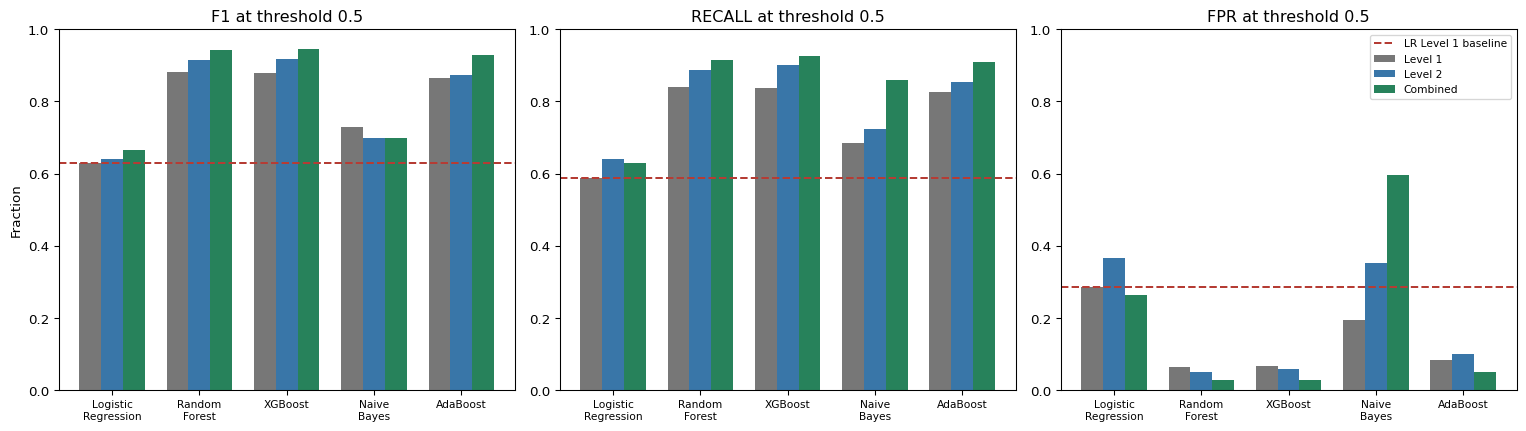

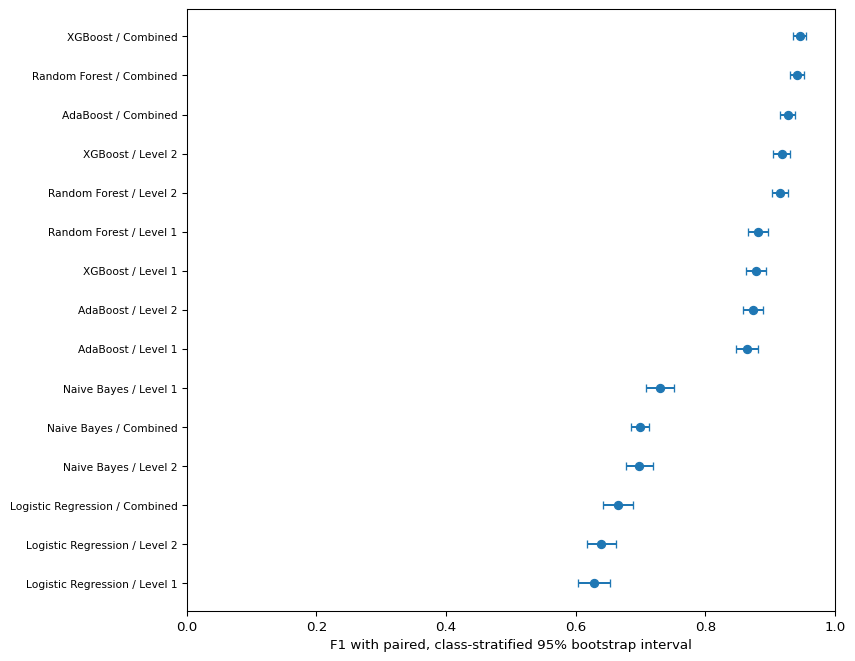

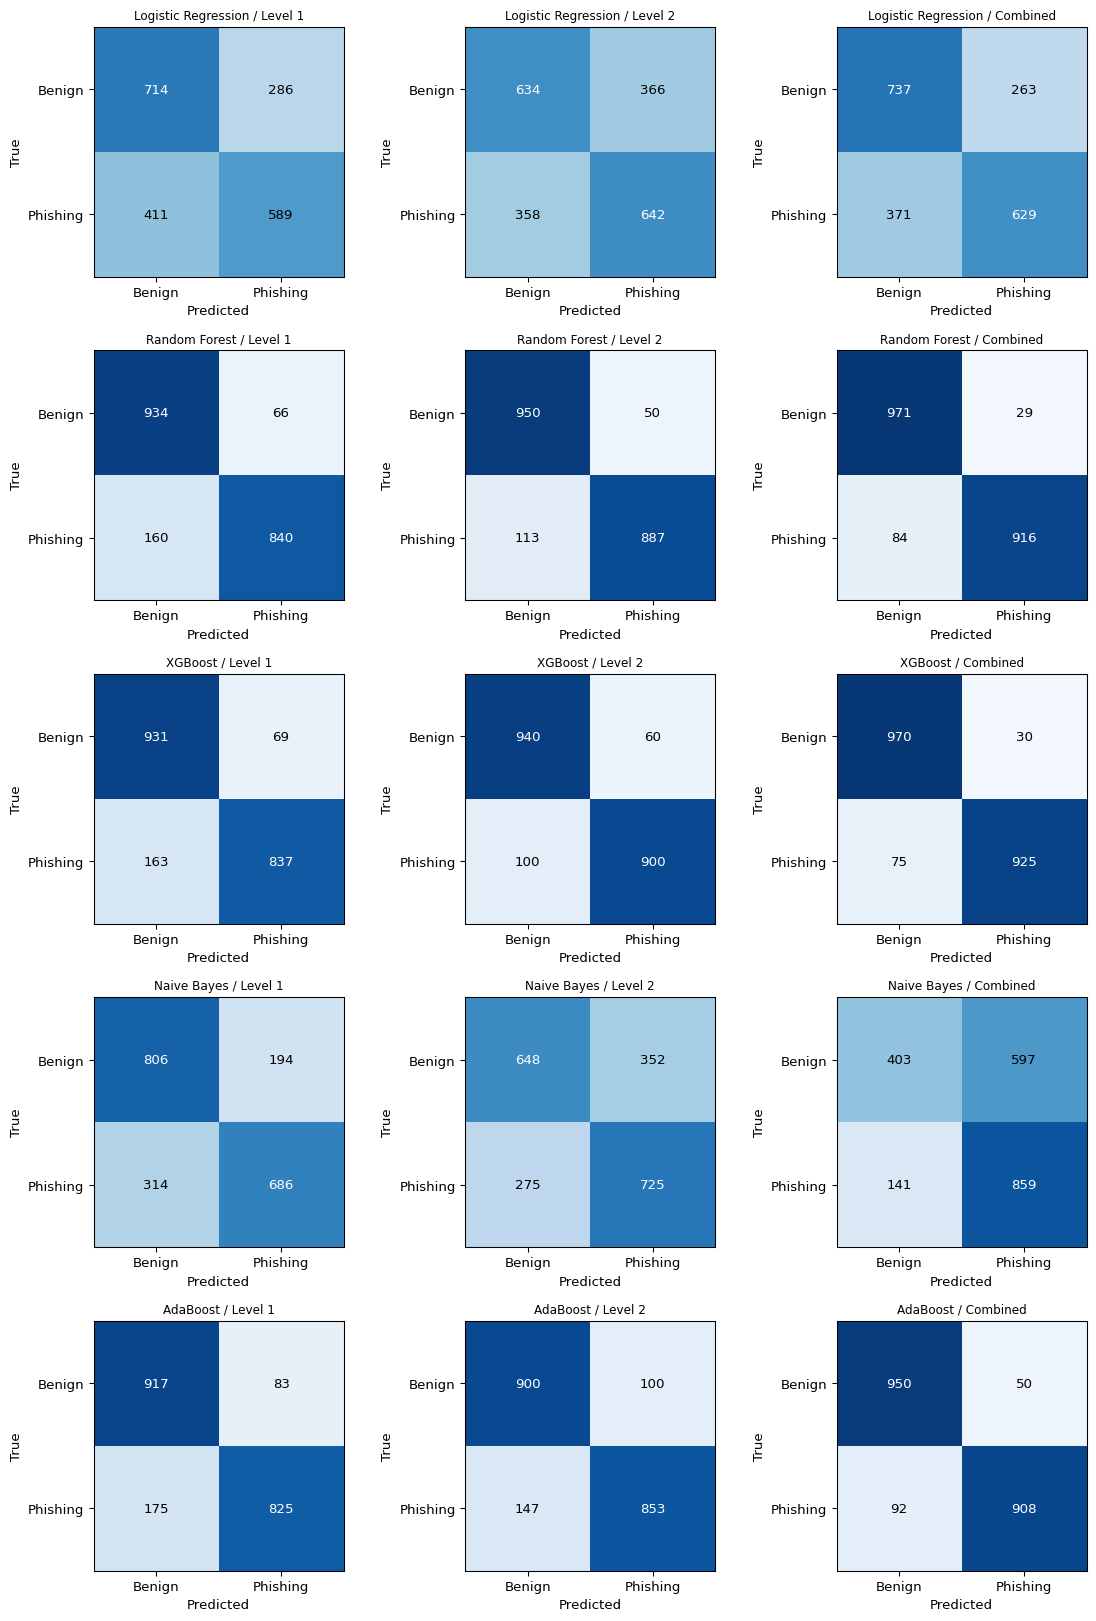

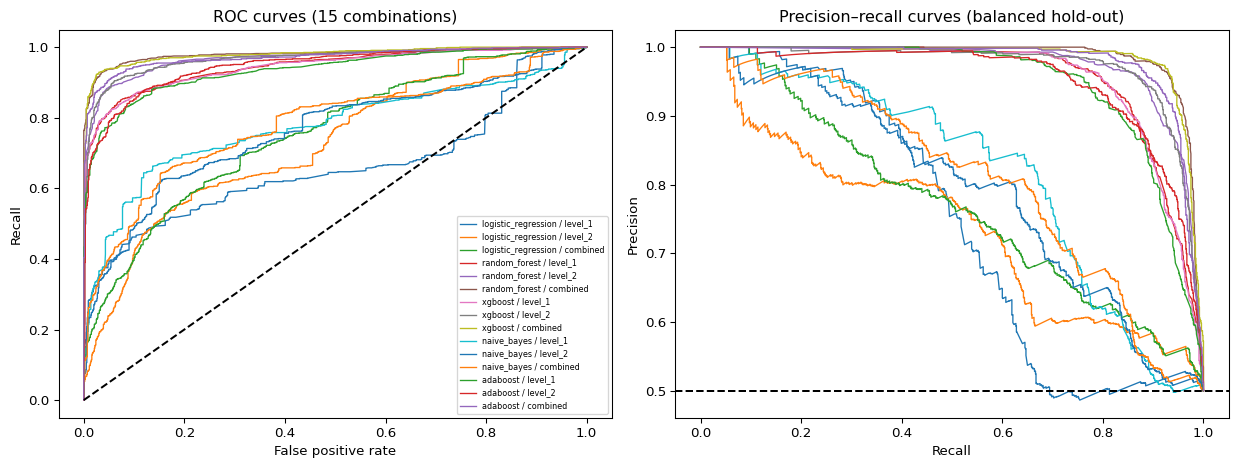

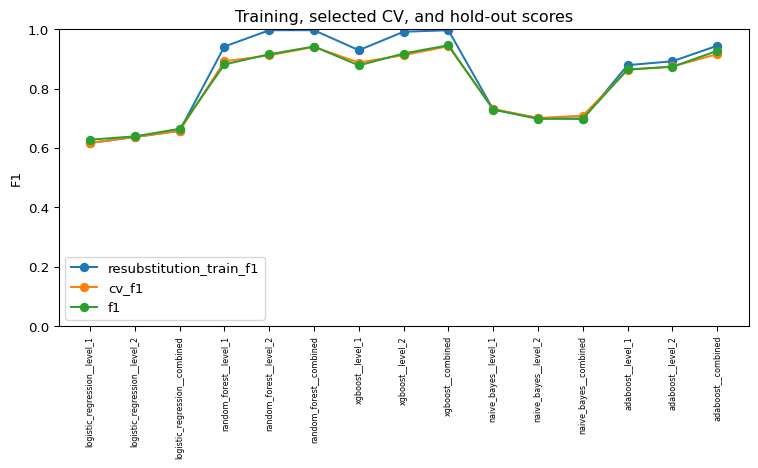

In [6]:
colors=['#777777','#3976A8','#27825B']
fig,axs=plt.subplots(1,3,figsize=(16,4.6))
for ax,metric in zip(axs,['f1','recall','fpr']):
    for j,f in enumerate(FS):
        v=results[results.feature_set==f].set_index('classifier').loc[CLASSIFIERS]
        ax.bar(np.arange(5)+(j-1)*.25,v[metric],.25,label=f,color=colors[j])
    ax.axhline(base[metric],ls='--',c='#B53C34',label='LR Level 1 baseline')
    ax.set_xticks(range(5),[c.replace(' ',chr(10)) for c in CLASSIFIERS],fontsize=8)
    ax.set_title(metric.upper()+' at threshold 0.5');ax.set_ylim(0,1)
axs[0].set_ylabel('Fraction');axs[-1].legend(fontsize=8)
figure('01_feature_comparison')

fig,ax=plt.subplots(figsize=(9,7));v=results.sort_values('f1').reset_index(drop=True)
ax.errorbar(v.f1,range(15),xerr=np.vstack([v.f1-v.f1_ci_low,v.f1_ci_high-v.f1]),fmt='o',capsize=3)
ax.set_yticks(range(15),v.classifier+' / '+v.feature_set,fontsize=8);ax.set_xlim(0,1)
ax.set_xlabel('F1 with paired, class-stratified 95% bootstrap interval');figure('02_f1_intervals')

fig,axs=plt.subplots(5,3,figsize=(12,17))
for i,c in enumerate(CLASSIFIERS):
 for j,f in enumerate(FS):
    row=results[(results.classifier==c)&(results.feature_set==f)].iloc[0];ax=axs[i,j]
    cm=np.array([[row.tn,row.fp],[row.fn,row.tp]],int)
    ax.imshow(cm,cmap='Blues',vmin=0,vmax=1000)
    for (a,b),v in np.ndenumerate(cm):ax.text(b,a,str(v),ha='center',va='center',color='white' if v>600 else 'black')
    ax.set_xticks([0,1],['Benign','Phishing']);ax.set_yticks([0,1],['Benign','Phishing'])
    ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title(c+' / '+f,fontsize=9)
figure('03_confusion_matrices_15')

fig,axs=plt.subplots(1,2,figsize=(13,5))
for k,p in probabilities.items():
    fpr,tpr,_=roc_curve(yt,p);prec,rec,_=precision_recall_curve(yt,p)
    axs[0].plot(fpr,tpr,label=k.replace('__',' / '),lw=1)
    axs[1].plot(rec,prec,lw=1)
axs[0].plot([0,1],[0,1],'k--');axs[1].axhline(yt.mean(),c='k',ls='--')
axs[0].set(xlabel='False positive rate',ylabel='Recall',title='ROC curves (15 combinations)')
axs[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curves (balanced hold-out)')
axs[0].legend(fontsize=6,loc='lower right');figure('04_roc_pr')

fig,ax=plt.subplots(figsize=(8,5))
for f in ['resubstitution_train_f1','cv_f1','f1']:
    ax.plot(np.arange(15),results[f],marker='o',label=f)
ax.set_xticks(range(15),results.combination,rotation=90,fontsize=6);ax.set_ylim(0,1)
ax.set_ylabel('F1');ax.legend();ax.set_title('Training, selected CV, and hold-out scores');figure('05_generalization_diagnostic')

## 6. Interpretability and probability diagnostics
For every combined model, permutation importance measures the change in hold-out **F1 at the fixed 0.5 threshold** after one feature is shuffled, with three seeded repetitions. This uses the complete test set. Correlated length/depth features can share signal, so importance is model-dependent and does not demonstrate causality. These diagnostics must not be used to reselect features on the same test set.

Reliability curves and Brier scores check probability behavior. No calibration is fitted here; Naïve Bayes and boosting probabilities may not be calibrated. A high score cannot be interpreted as a validated probability of obfuscation.

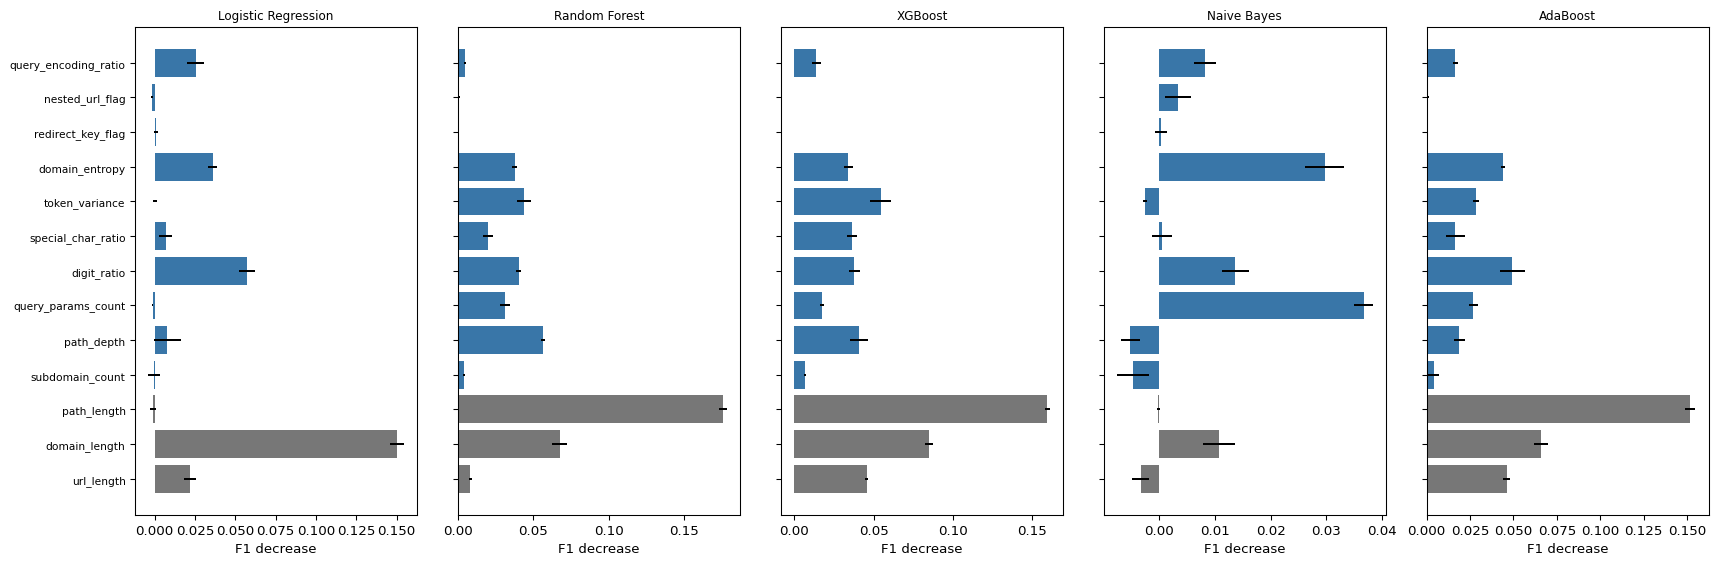

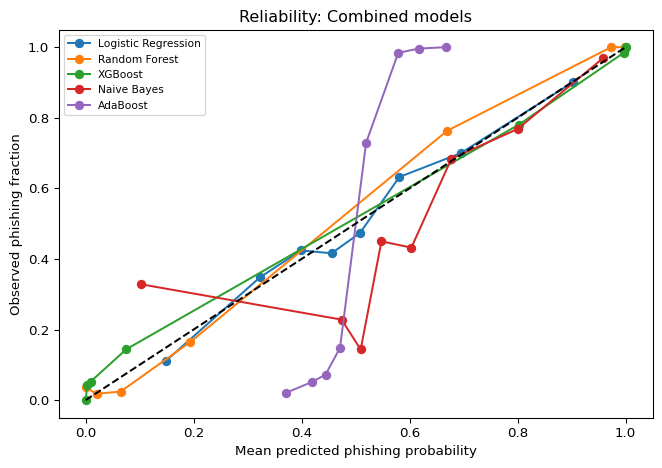

In [7]:
importance=[];perm_rng=np.random.default_rng(SEED)
for c in CLASSIFIERS:
    k=key(c,'Combined'); model=bundles[k]['model']; X=data.iloc[test_idx][L1+L2].to_numpy(float)
    score=f1_score(yt,predictions[k])
    for j,f in enumerate(L1+L2):
        drops=[]
        for rep in range(3):
            xp=X.copy();xp[:,j]=xp[perm_rng.permutation(len(xp)),j]
            pp=model.predict_proba(xp)[:,1]
            drops.append(score-f1_score(yt,pp>=.5))
        importance.append(dict(classifier=c,feature=f,level='Level 1' if f in L1 else 'Level 2',
                               f1_drop_mean=float(np.mean(drops)),f1_drop_std=float(np.std(drops)),repeats=3,n=len(yt)))
importance=pd.DataFrame(importance);save_table(importance,'permutation_importance_combined')
fig,axs=plt.subplots(1,5,figsize=(18,6),sharey=True)
for ax,c in zip(axs,CLASSIFIERS):
    v=importance[importance.classifier==c].set_index('feature').loc[L1+L2]
    ax.barh(range(13),v.f1_drop_mean,xerr=v.f1_drop_std,color=[colors[0] if f in L1 else colors[1] for f in L1+L2])
    ax.set_yticks(range(13),L1+L2,fontsize=8);ax.set_title(c,fontsize=9);ax.set_xlabel('F1 decrease')
figure('06_permutation_importance')
fig,ax=plt.subplots(figsize=(7,5))
for c in CLASSIFIERS:
    p=probabilities[key(c,'Combined')]
    obs,mean=calibration_curve(yt,p,n_bins=8,strategy='quantile')
    ax.plot(mean,obs,'o-',label=c)
ax.plot([0,1],[0,1],'k--');ax.set(xlabel='Mean predicted phishing probability',ylabel='Observed phishing fraction',title='Reliability: Combined models')
ax.legend(fontsize=8);figure('07_probability_reliability')

## 7. Resource comparison and extraction evidence
Training resource figures belong to the original recorded environment. The original resource sampler polls the main process RSS; it may miss short peaks. Current inference is serial, warmed up, one timed call per URL (2,000 timed calls/model), with mean, median, and p95. Model sizes are disk sizes, not resident memory.

The extraction notebook displays rounded per-phase wall times in its saved output. The code below reads those **recorded outputs**, rather than pretending that CSV loading is feature extraction. Shared parsing cost is added to each feature configuration. These are historical, rounded measurements; the combined total may differ slightly from the sum due to rounding. They were not measured in this runtime and are not end-to-end deployment latency. If the extraction output changes format or is missing, the measure remains unavailable and is explicitly reported.

,combination,classifier,feature_set,training_time_s_historical,training_peak_rss_mb_historical,training_peak_rss_increase_mb_historical,inference_ms_per_url_historical,inference_mean_ms_current,inference_p50_ms_current,inference_p95_ms_current,timed_calls,model_size_mb,extraction_10000_urls_s_historical_rounded,extraction_source
0,logistic_regression__level_1,Logistic Regression,Level 1,0.9506,253.7695,12.1250,0.0544,0.0367,0.0310,0.0626,2000,0.0013,0.083,Module 3–4 saved rounded profile table; shared...
1,logistic_regression__level_2,Logistic Regression,Level 2,2.5523,278.8047,26.3047,0.0413,0.0360,0.0311,0.0564,2000,0.0015,0.393,Module 3–4 saved rounded profile table; shared...
2,logistic_regression__combined,Logistic Regression,Combined,4.6696,288.3047,5.3867,0.0429,0.0360,0.0312,0.0557,2000,0.0015,0.396,Module 3–4 saved rounded profile table; shared...
3,random_forest__level_1,Random Forest,Level 1,45.8857,289.1680,26.3047,1.9672,1.9872,1.9085,2.3840,2000,9.4823,0.083,Module 3–4 saved rounded profile table; shared...
4,random_forest__level_2,Random Forest,Level 2,146.4552,282.6094,29.3516,2.3375,1.9113,1.8472,2.2231,2000,12.7035,0.393,Module 3–4 saved rounded profile table; shared...
5,random_forest__combined,Random Forest,Combined,154.3317,288.4961,20.3867,7.8013,5.5233,5.4194,6.2288,2000,29.3302,0.396,Module 3–4 saved rounded profile table; shared...
6,xgboost__level_1,XGBoost,Level 1,36.8088,297.6250,6.9688,0.9659,0.1813,0.1569,0.3014,2000,0.5493,0.083,Module 3–4 saved rounded profile table; shared...
7,xgboost__level_2,XGBoost,Level 2,54.9609,301.2500,5.3750,1.1795,0.1921,0.1664,0.3107,2000,0.8667,0.393,Module 3–4 saved rounded profile table; shared...
8,xgboost__combined,XGBoost,Combined,42.4544,303.4180,6.3125,0.4509,0.1890,0.1644,0.3139,2000,0.8257,0.396,Module 3–4 saved rounded profile table; shared...
9,naive_bayes__level_1,Naive Bayes,Level 1,0.1284,297.9531,0.0195,0.1426,0.1230,0.1040,0.2219,2000,0.0012,0.083,Module 3–4 saved rounded profile table; shared...


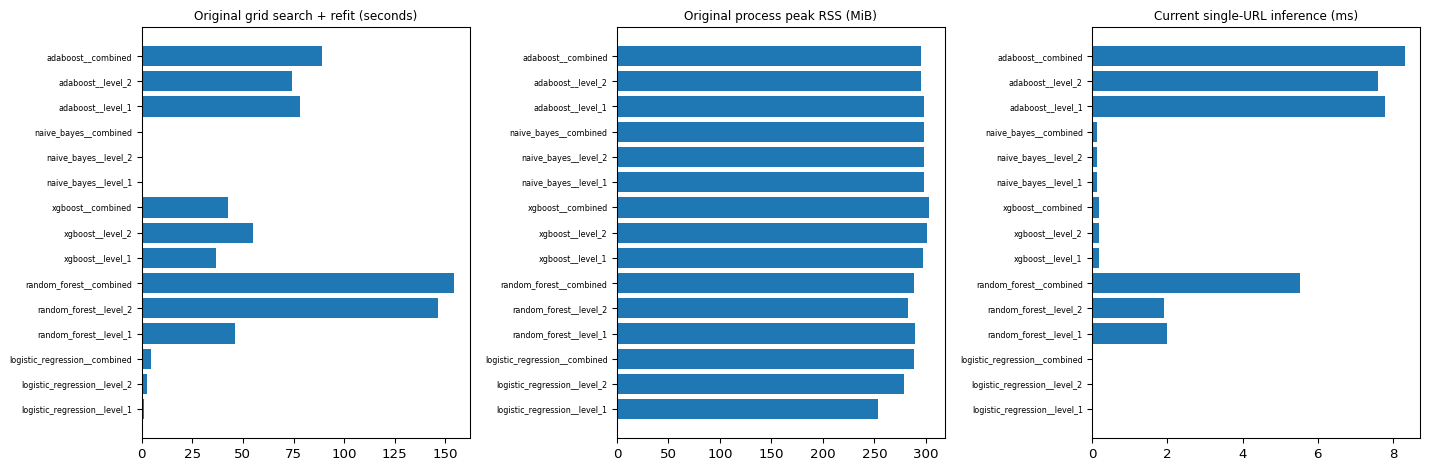

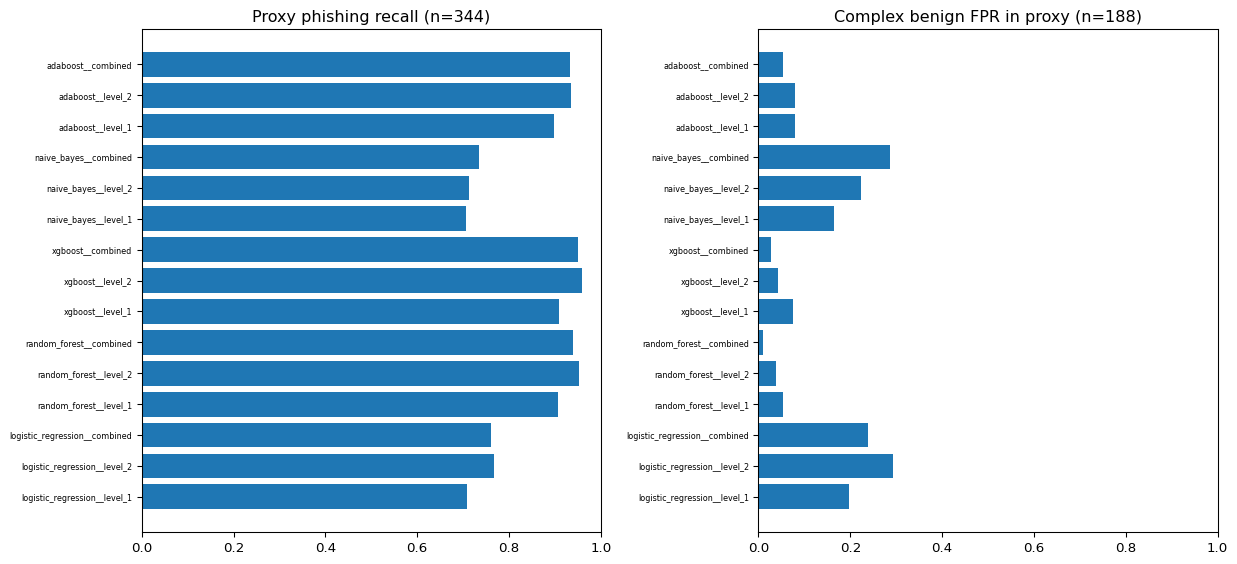

In [8]:
exnb=json.loads((ROOT/'Modules/3_4_feature_extraction_pipeline.ipynb').read_text())
phase_times={}
for cell in exnb['cells']:
    if 'profile_table.round' not in ''.join(cell.get('source',[])): continue
    for out in cell.get('outputs',[]):
        text=''.join(out.get('data',{}).get('text/plain',[]))
        for line in text.splitlines():
            match=re.match(r'^\s*([0-5])\s+(.+?)\s+(\d+)\s+\d{2}:\d{2}:\d{2}\s+\d{2}:\d{2}:\d{2}\s+([\d.]+)',line)
            if match:phase_times[int(match[1])]=float(match[4])
extraction={'Level 1':phase_times.get(0,np.nan)+phase_times.get(1,np.nan),
            'Level 2':phase_times.get(0,np.nan)+phase_times.get(4,np.nan),
            'Combined':phase_times.get(5,np.nan)}
resources=results[['combination','classifier','feature_set','training_time_s_historical',
    'training_peak_rss_mb_historical','training_peak_rss_increase_mb_historical',
    'inference_ms_per_url_historical','inference_mean_ms_current','inference_p50_ms_current','inference_p95_ms_current','timed_calls']].copy()
resources=resources.merge(pd.DataFrame(model_audit)[['combination','model_size_mb']],on='combination',validate='one_to_one')
resources['extraction_10000_urls_s_historical_rounded']=resources.feature_set.map(extraction)
resources['extraction_source']='Module 3–4 saved rounded profile table; shared parsing included'
save_table(resources,'resource_comparison');display(resources.round(4))
fig,axs=plt.subplots(1,3,figsize=(15,5))
for ax,col,title in zip(axs,['training_time_s_historical','training_peak_rss_mb_historical','inference_mean_ms_current'],
                       ['Original grid search + refit (seconds)','Original process peak RSS (MiB)','Current single-URL inference (ms)']):
    ax.barh(range(15),resources[col]);ax.set_yticks(range(15),resources.combination,fontsize=6);ax.set_title(title,fontsize=9)
figure('08_resource_profile')
# Subset plots include support and explicitly use the proxy label.
fig,axs=plt.subplots(1,2,figsize=(13,6))
v=subsets[subsets.slice=='evasion_indicator_proxy'].set_index('combination').loc[results.combination]
axs[0].barh(range(15),v.recall);axs[1].barh(range(15),v.fpr)
for ax in axs:ax.set_yticks(range(15),results.combination,fontsize=6);ax.set_xlim(0,1)
axs[0].set_title('Proxy phishing recall (n='+str(int(v.n_phishing.iloc[0]))+')')
axs[1].set_title('Complex benign FPR in proxy (n='+str(int(v.n_benign.iloc[0]))+')')
figure('09_proxy_subset')

## 8. Evidence package, limitations, and completion checks
The primary table has exactly **15 rows** and one baseline reference. The baseline is one of the 15 combinations; the separately saved Module 6 artifact is a consistency check, not a sixteenth candidate. All metrics are recomputed from loaded models, not copied from saved scores.

**Conclusions that remain out of scope:** no zero-day/temporal guarantee, no verified evasion-heavy ground truth, no demonstrated advantage over an untrained deep learning comparator, no live browsing/gateway claim, and no independent final-test confirmation. The proposal has inconsistencies beyond the milestone form: some narrative passages request component-wise entropy/ratios while Table 4.1 specifies a single domain entropy and URL-wide ratios. This experiment evaluates the implemented Table 4.1 representation. Normalizing the whole URL to lowercase can alter case-sensitive paths and Base64 payloads; a separate feature-extraction audit is required before claiming complete coverage of encoded attacks.

**Required correction before final thesis claims:** deduplicate again after normalization, check labels, then retrain Module 6/7 on the regenerated raw features with MinMax/Standard scaling and binary passthrough inside a `ColumnTransformer` + `Pipeline` nested in GridSearchCV; persist the fitted preprocessors with each model. Keep the proposal's 0.5 threshold primary. Save input hashes, split row order, fold assignments, full CV results, all 15 bundles, and comparable per-run resource records. Reevaluate with these notebooks adapted to read the persisted pipelines. Because present test results are known, final confirmation also needs a new independently collected, labelled, domain-disjoint/temporal test set. Do not just rescale the existing model inputs: that would change the coordinate system without retraining.

Primary methods reference: [scikit-learn: data leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [9]:
assert len(results)==15 and set(zip(results.classifier,results.feature_set))==expected
assert results[['accuracy','precision','recall','f1','fpr','fnr','roc_auc','average_precision']].notna().all().all()
assert (results[['tn','fp','fn','tp']].sum(axis=1)==len(yt)).all()
assert all(len(p)==2000 for p in probabilities.values())
assert len(paired)==24 and len(model_audit)==15
hash_paths=['Dataset/Final_Dataset.csv','Dataset/Extracted_Features.csv','Dataset/Preprocessed_Dataset.csv',
            'Models/train_test_split_indices.csv','Metrics/models_manifest.csv','Metrics/all_models_metrics.json',
            'Models/baseline_logistic_regression.joblib']
metadata=dict(study='Obfuscation-Aware Feature Engineering for Evasion-Heavy Phishing URL Detection',
    source_commit_reviewed='1178f6aa41318b34f7b7c8522cf1f867cb74f06b',
    status='PROVISIONAL: original preprocessing leakage and previously inspected test set',
    threshold=.5,seed=SEED,n_boot=N_BOOT,n_test=len(yt),class_counts={'benign':1000,'phishing':1000},
    heuristic_subset_cutoffs=cutoffs,feature_sets=FS,training_environment=record['environment'],
    evaluation_environment=dict(python=platform.python_version(),sklearn=sklearn.__version__,xgboost=xgboost.__version__,
        pandas=pd.__version__,numpy=np.__version__,scipy=scipy.__version__,platform=platform.platform(),
        logical_cpus=psutil.cpu_count(),ram_gb=psutil.virtual_memory().total/2**30,native_threads=1),
    input_sha256={p:sha(ROOT/p) for p in hash_paths},
    caveats=['scaling fitted on all rows before splitting and CV','test scores previously displayed in Modules 6 and 7',
             'evasion subsets are heuristics, not validated evasion labels','RSS includes retained models and runtime',
             'row bootstrap assumes independent URLs; domains may be shared','test ranking is exploratory; do not retune from it'])
(OUT/'evaluation_metadata.json').write_text(json.dumps(metadata,indent=2))
np.savez_compressed(OUT/'prediction_arrays.npz',row_index=test_idx,y_true=yt,**probabilities)
print('Milestone 8 implementation complete: 15-combination table, verified baseline, paired comparisons,')
print('uncertainty, error/subset analysis, importance, probability diagnostics, and resource figures exported.')
print('Scientific readiness: PROVISIONAL — see limitations and Module 7 audit before final thesis claims.')
print('Next: run 9_preliminary_findings_results_writeup.ipynb. Outputs:', OUT)

Milestone 8 implementation complete: 15-combination table, verified baseline, paired comparisons,
uncertainty, error/subset analysis, importance, probability diagnostics, and resource figures exported.
Scientific readiness: PROVISIONAL — see limitations and Module 7 audit before final thesis claims.
Next: run 9_preliminary_findings_results_writeup.ipynb. Outputs: /workspace/scratch/e3e5f7f7f0e0/full_repo/Results/milestone8
